# plutovizu — Graphiques seaborn

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Données d'exemple

Jeux de données fictifs utilisés dans ce notebook.

In [2]:
rng = np.random.default_rng(3)
lignes = []
for variete, gain in [('Sahel-108', 0.0), ('IR-841', 0.7), ('Nerica-4', 1.3)]:
    for dose in [0, 30, 60, 90, 120]:
        for bloc in range(1, 5):
            lignes.append({'variete': variete, 'dose': dose, 'bloc': bloc,
                           'rendement': 2.5 + gain + 0.035 * dose - 0.00018 * dose ** 2
                                        + rng.normal(0, 0.3)})
essai = pd.DataFrame(lignes)

rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

## Graphiques seaborn

`chart.seaborn('nom')` donne accès à toutes les fonctions de seaborn ; les plus courantes ont un raccourci (`kde`, `swarm`, `pairplot`, `jointplot`…).

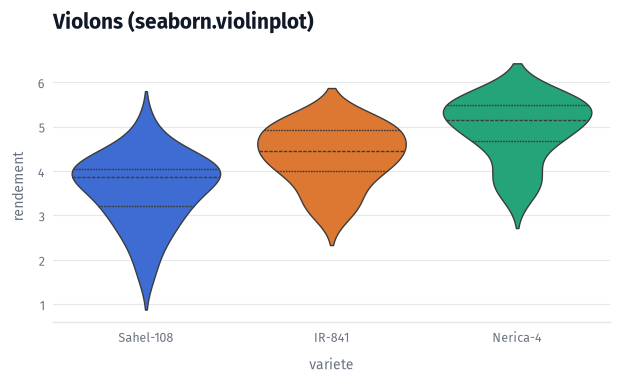

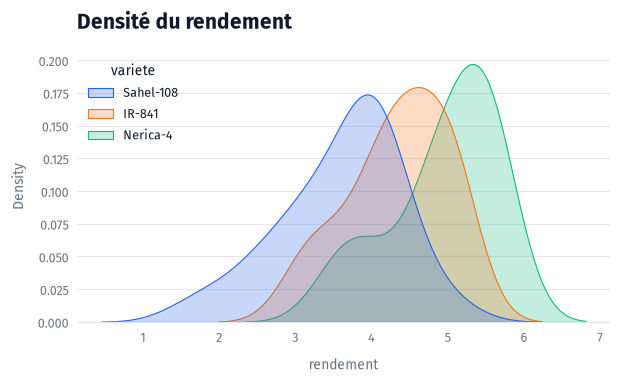

In [3]:
(Chart(essai)
    .seaborn('violinplot', x='variete', y='rendement', hue='variete', inner='quart')
    .title('Violons (seaborn.violinplot)')
    .tight_layout()
    .show())

(Chart(essai)
    .kde('rendement', hue='variete')
    .title('Densité du rendement')
    .tight_layout()
    .show())

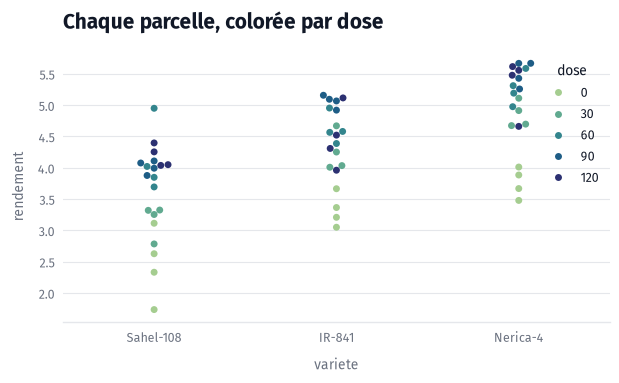

In [4]:
(Chart(essai)
    .swarm('variete', 'rendement', hue='dose', palette='crest')
    .title('Chaque parcelle, colorée par dose')
    .tight_layout()
    .show())

Les fonctions seaborn à plusieurs panneaux remplacent la figure : `title()` devient le titre général.

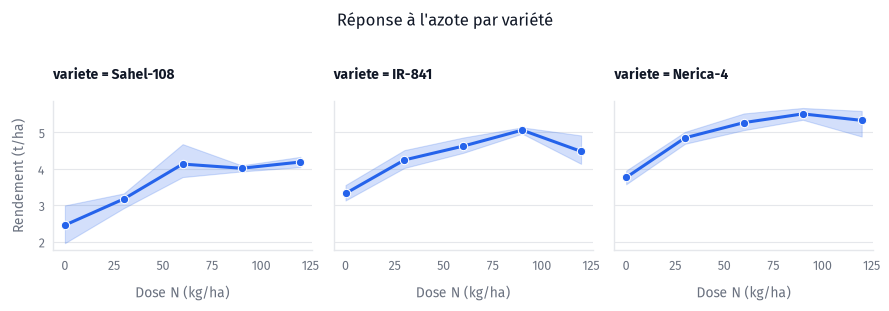

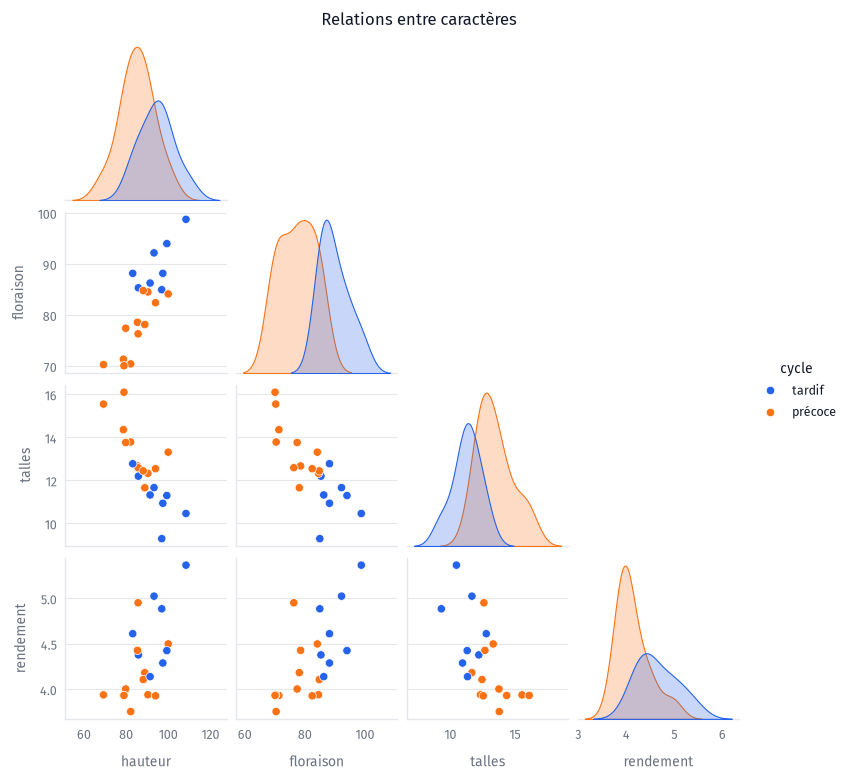

In [5]:
(Chart(essai)
    .seaborn('relplot', x='dose', y='rendement', col='variete', kind='line', marker='o', height=3)
    .title("Réponse à l'azote par variété")
    .labels('Dose N (kg/ha)', 'Rendement (t/ha)')
    .tight_layout()
    .show())

(Chart(caracteres)
    .pairplot(vars=['hauteur', 'floraison', 'talles', 'rendement'], hue='cycle', corner=True, height=1.9)
    .title('Relations entre caractères')
    .show())